In [3]:
import os, glob, random, shutil, subprocess, zipfile, json, time
import numpy as np
import pandas as pd
import torch

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

INPUT_ROOT  = "/kaggle/input"
EXTRACT_DIR = "/kaggle/temp/data"   # unzipped images go here (not saved as notebook output)
os.makedirs(EXTRACT_DIR, exist_ok=True)

# 1. Unzip every .zip found in the inputs (e.g. the zipped output of the preprocessing notebook)
zips = sorted(glob.glob(os.path.join(INPUT_ROOT, "**", "*.zip"), recursive=True))
print("Zip files found:", zips if zips else "none")
for z in zips:
    dest = os.path.join(EXTRACT_DIR, os.path.splitext(os.path.basename(z))[0])
    if os.path.exists(os.path.join(dest, ".unzipped")):
        print("  already unzipped:", dest)
        continue
    os.makedirs(dest, exist_ok=True)
    t0 = time.time()
    if shutil.which("unzip"):
        subprocess.run(["unzip", "-q", "-o", z, "-d", dest], check=True)
    else:
        with zipfile.ZipFile(z) as zf:
            zf.extractall(dest)
    open(os.path.join(dest, ".unzipped"), "w").close()
    print(f"  unzipped {os.path.basename(z)} -> {dest}  ({time.time()-t0:.0f}s)")

# 2. Where to look for images: the unzipped folder (or a 'processed' folder if nothing was zipped)
if zips:
    IMAGE_ROOTS = [EXTRACT_DIR]
else:
    IMAGE_ROOTS = sorted(glob.glob(os.path.join(INPUT_ROOT, "**", "processed"), recursive=True))
print("Image folders:", IMAGE_ROOTS)

MANIFEST = None   # leave None to find it automatically, or paste a CSV path here
# 3. Find the manifest: a CSV with filename / grade / split columns
if MANIFEST is None:
    REQUIRED = {"filename", "grade", "split"}
    found = []
    for root in IMAGE_ROOTS + [INPUT_ROOT]:
        for c in glob.glob(os.path.join(root, "**", "*.csv"), recursive=True):
            try:
                if REQUIRED <= set(pd.read_csv(c, nrows=1).columns):
                    found.append(c)
            except Exception:
                pass
    found = sorted(set(found), key=lambda c: (not any(k in os.path.basename(c).lower()
                                                     for k in ("manifest", "dr_all")), c))
    print("Manifest candidates:", found)
    assert found, "No CSV with filename/grade/split columns found - set MANIFEST manually."
    MANIFEST = found[0]
print("Using manifest:", MANIFEST)

# 4. Index every image by filename so the manifest can be matched to files
IMG_EXT = (".jpg", ".jpeg", ".png")
file_index = {}
for root in IMAGE_ROOTS:
    for dirpath, _, files in os.walk(root):
        for f in files:
            if f.lower().endswith(IMG_EXT):
                file_index.setdefault(f, []).append(os.path.join(dirpath, f))
print(f"Images found: {sum(len(v) for v in file_index.values()):,} files, {len(file_index):,} unique names")

Zip files found: ['/kaggle/input/notebooks/lohitashwamadhan/02-preprocessing/_output_.zip']
  unzipped _output_.zip -> /kaggle/temp/data/_output_  (194s)
Image folders: ['/kaggle/temp/data']
Manifest candidates: ['/kaggle/temp/data/_output_/manifest_v2.csv']
Using manifest: /kaggle/temp/data/_output_/manifest_v2.csv
Images found: 177,678 files, 88,839 unique names


Image copies found:
  _output_/processed                                           88,839 images
  _output_/processed_bg                                        88,839 images

Using Ben Graham images from: _output_/processed_bg
Images kept: 88,839 files, 88,839 unique names


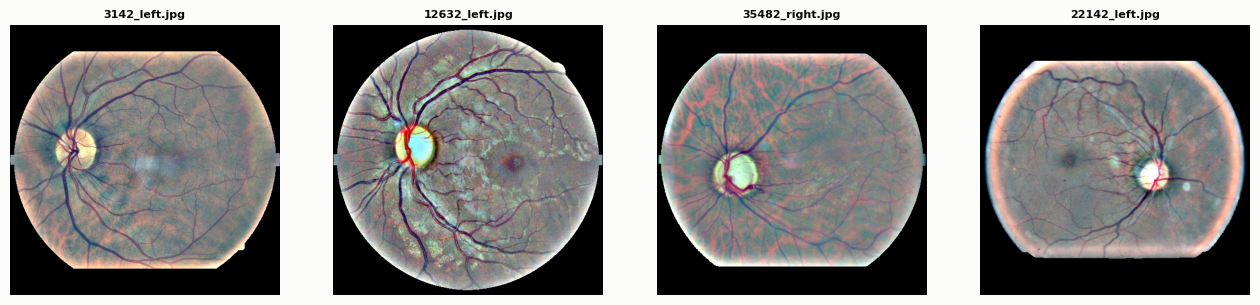

In [4]:
from collections import Counter
import matplotlib.pyplot as plt
from PIL import Image

BG_FOLDER = None   # None = auto-detect (it found "_output_/processed_bg" before)

copies = Counter()
for paths in file_index.values():
    for p in paths:
        rel = os.path.relpath(p, EXTRACT_DIR).split(os.sep)
        copies[os.sep.join(rel[:-2])] += 1
print("Image copies found:")
for folder, n in copies.most_common():
    print(f"  {folder:60s} {n:,} images")

if BG_FOLDER is None:
    keys = ("ben", "graham", "bg", "gaussian")
    bg_candidates = [f for f in copies if any(k in f.lower() for k in keys)]
    assert len(bg_candidates) == 1, f"Could not auto-detect the Ben Graham folder from {list(copies)} - set BG_FOLDER manually."
    BG_FOLDER = bg_candidates[0]
print("\nUsing Ben Graham images from:", BG_FOLDER)

file_index = {f: [p for p in paths if f"{os.sep}{BG_FOLDER}{os.sep}" in f"{os.sep}{os.path.relpath(p, EXTRACT_DIR)}"]
              for f, paths in file_index.items()}
file_index = {f: ps for f, ps in file_index.items() if ps}
print(f"Images kept: {sum(len(v) for v in file_index.values()):,} files, {len(file_index):,} unique names")

sample = random.sample(list(file_index.values()), 4)
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, ps in zip(axes, sample):
    ax.imshow(Image.open(ps[0])); ax.axis("off"); ax.set_title(os.path.basename(ps[0]), fontsize=8)
plt.show()

In [5]:
USE_OFFICIAL_VAL = True        # True = validate on the shared val split (same for every experiment)
ADD_BACK_UNDERSAMPLED = False  # True = put the No-DR images removed by undersampling back into train (imbalanced run)
BALANCE_TOLERANCE = 0.10       # train counts as balanced if DR is between 40% and 60%

df = pd.read_csv(MANIFEST)
if "load_ok" in df.columns:
    df = df[df["load_ok"] == True].copy()
df["label"] = (df["grade"] >= 1).astype(int)

if ADD_BACK_UNDERSAMPLED and "excluded_reason" in df.columns:
    m = df["excluded_reason"].eq("undersampled_no_DR")
    df.loc[m, "split"] = "train"
    print(f"Added back {m.sum():,} undersampled No-DR images -> imbalanced training set")

def pick_path(fname, split):
    paths = file_index.get(fname)
    if not paths:
        return None
    for p in paths:
        if f"{os.sep}{split}{os.sep}" in p:
            return p
    return paths[0]

df["path"] = [pick_path(f, s) for f, s in zip(df["filename"], df["split"])]

train_df = df[df["split"] == "train"].copy()
if USE_OFFICIAL_VAL:
    val_df = df[df["split"] == "val"].copy()
    val_source = "official val split"
else:
    from sklearn.model_selection import GroupShuffleSplit
    gss = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
    fit_i, chk_i = next(gss.split(train_df, groups=train_df["group_id"]))
    val_df = train_df.iloc[chk_i].copy(); train_df = train_df.iloc[fit_i].copy()
    val_source = "15% patient hold-out from train"

for name, d in [("train", train_df), ("val", val_df)]:
    miss = d["path"].isna().sum()
    if miss:
        print(f"WARNING: {miss:,} {name} images not found - they will be skipped")
train_df = train_df[train_df["path"].notna()].reset_index(drop=True)
val_df = val_df[val_df["path"].notna()].reset_index(drop=True)

if "group_id" in df.columns:
    print("Patients in both train and val:", len(set(train_df["group_id"]) & set(val_df["group_id"])))

dr_frac = train_df["label"].mean()
IS_BALANCED = abs(dr_frac - 0.5) <= BALANCE_TOLERANCE
print(f"\nTrain: {len(train_df):,} images | DR {dr_frac*100:.1f}% | grades {train_df['grade'].value_counts().sort_index().to_dict()}")
print(f"Val ({val_source}): {len(val_df):,} images | DR {val_df['label'].mean()*100:.1f}%")
print("Test: not loaded (kept untouched for the final evaluation)")
print(f"\nTraining set is {'BALANCED' if IS_BALANCED else 'IMBALANCED'} "
      f"({'normal shuffled batches' if IS_BALANCED else 'batch balancing ON: 40% DR / 60% No-DR per batch'})")

Patients in both train and val: 0

Train: 30,287 images | DR 50.1% | grades {0: 15126, 1: 2982, 2: 9922, 3: 713, 4: 1544}
Val (official val split): 6,483 images | DR 24.5%
Test: not loaded (kept untouched for the final evaluation)

Training set is BALANCED (normal shuffled batches)


In [6]:
class BalancedBatchSampler:
    """
    Builds every training batch with a fixed DR / No-DR mix (default 40% DR, 60% No-DR).

    - No-DR (majority): drawn WITHOUT replacement from a shuffled pool that carries over
      between epochs, so over several epochs every No-DR image gets used.
    - DR (minority): drawn from its own shuffled pool; when the pool runs out it is
      reshuffled, so DR images repeat. Each draw is yielded as (index, is_repeat):
      is_repeat=True when that DR image was already used earlier in the same epoch,
      which tells the Dataset to apply the stronger augmentation.
    - Keeps a record of how often every DR image index was used (per epoch and in total).
    """
    def __init__(self, labels, batch_size=32, dr_frac=0.40, seed=42):
        labels = np.asarray(labels).astype(int)
        self.dr_idx = np.where(labels == 1)[0]
        self.no_idx = np.where(labels == 0)[0]
        self.n_dr = int(round(batch_size * dr_frac))
        self.n_no = batch_size - self.n_dr
        self.num_batches = len(labels) // batch_size        # same number of images per epoch as the dataset
        self.rng = np.random.default_rng(seed)
        self.py_rng = random.Random(seed)
        self.pools = {"dr": [], "no": []}
        self.dr_use_total = np.zeros(len(labels), dtype=int)  # total uses per image index
        self.last_epoch_counts = np.zeros(len(labels), dtype=int)
        self.epoch_log = []

    def _draw(self, key, all_idx, k):
        out = []
        while len(out) < k:
            if not self.pools[key]:
                self.pools[key] = self.rng.permutation(all_idx).tolist()
            out.append(self.pools[key].pop())
        return out

    def __len__(self):
        return self.num_batches

    def __iter__(self):
        counts = np.zeros(len(self.dr_use_total), dtype=int)
        for _ in range(self.num_batches):
            batch = []
            for i in self._draw("dr", self.dr_idx, self.n_dr):
                counts[i] += 1
                batch.append((int(i), bool(counts[i] > 1)))
            for i in self._draw("no", self.no_idx, self.n_no):
                counts[i] += 1
                batch.append((int(i), False))
            self.py_rng.shuffle(batch)
            yield batch
        self.last_epoch_counts = counts
        self.dr_use_total += counts * np.isin(np.arange(len(counts)), self.dr_idx)
        used = counts[self.dr_idx]
        self.epoch_log.append({
            "epoch": len(self.epoch_log) + 1,
            "dr_draws": int(used.sum()),
            "unique_dr_used": int((used > 0).sum()),
            "dr_total": int(len(self.dr_idx)),
            "repeated_dr_draws": int(np.clip(used - 1, 0, None).sum()),
            "max_uses_one_dr_image": int(used.max()),
            "no_dr_draws": int(counts[self.no_idx].sum()),
            "unique_no_dr_used": int((counts[self.no_idx] > 0).sum()),
            "no_dr_total": int(len(self.no_idx)),
        })


from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

IMG_SIZE = 512
BATCH = 32
DR_BATCH_FRAC = 0.40     # imbalanced runs only: 40% DR / 60% No-DR in every batch
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

RUN_NAME = f"auc_loss_{IMG_SIZE}_bengraham_{'balanced' if IS_BALANCED else 'imbalanced_batchbal'}"
OUT_DIR = f"/kaggle/working/{RUN_NAME}"
os.makedirs(OUT_DIR, exist_ok=True)

# Standard augmentation for every training image
train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
# Stronger augmentation for a DR image that is REPEATED within the same epoch (imbalanced runs)
repeat_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.85, 1.0), ratio=(0.95, 1.05)),   # mild zoom
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(30),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
# Validation: no augmentation
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

class DRDataset(Dataset):
    """Returns (image, label, index). Items can be an index, or (index, is_repeat) from the sampler."""
    def __init__(self, frame, tf, repeat_tf=None):
        self.paths = frame["path"].values
        self.labels = frame["label"].values.astype("float32")
        self.tf, self.repeat_tf = tf, repeat_tf

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, item):
        idx, is_repeat = item if isinstance(item, tuple) else (item, False)
        img = Image.open(self.paths[idx]).convert("RGB")
        tf = self.repeat_tf if (is_repeat and self.repeat_tf is not None) else self.tf
        return tf(img), torch.tensor(self.labels[idx]), int(idx)

train_ds = DRDataset(train_df, train_tf, repeat_tf)
val_ds = DRDataset(val_df, eval_tf)

if IS_BALANCED:
    sampler = None
    train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True, drop_last=True,
                              num_workers=4, pin_memory=True)
else:
    sampler = BalancedBatchSampler(train_df["label"].values, BATCH, DR_BATCH_FRAC, SEED)
    train_loader = DataLoader(train_ds, batch_sampler=sampler, num_workers=4, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=64, shuffle=False, num_workers=4, pin_memory=True)

# Check: every train and val image must come from the Ben Graham folder
not_bg = sum(f"{os.sep}processed_bg{os.sep}" not in p for p in pd.concat([train_df["path"], val_df["path"]]))
print("Images NOT from processed_bg:", not_bg)
assert not_bg == 0, "Some images are not Ben Graham - rerun Cell 1 and Cell 1b."

print("Run name:", RUN_NAME)
print("Batches per epoch:", len(train_loader))
if sampler is not None:
    print(f"Each batch: {sampler.n_dr} DR + {sampler.n_no} No-DR "
          f"({sampler.n_dr/BATCH:.0%} / {sampler.n_no/BATCH:.0%})")
x, y, _ = next(iter(train_loader))
print("Example batch:", tuple(x.shape), "| DR in batch:", int(y.sum()), "of", len(y))

Images NOT from processed_bg: 0
Run name: auc_loss_512_bengraham_balanced
Batches per epoch: 946
Example batch: (32, 3, 512, 512) | DR in batch: 20 of 32


In [7]:
import torch.nn as nn

class BaselineCNN(nn.Module):
    def __init__(self, channels=(32, 64, 128, 256), dropout=0.3):
        super(BaselineCNN, self).__init__()
        self.blocks = nn.ModuleList()
        in_channels = 3
        for out_channels in channels:
            block = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(),
                nn.MaxPool2d(kernel_size=2),
            )
            self.blocks.append(block)
            in_channels = out_channels
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(channels[len(channels) - 1], 1)

    def forward(self, x):
        for block in self.blocks:
            x = block(x)
        x = self.pool(x)
        x = x.view(x.size(0), -1)
        x = self.dropout(x)
        x = self.fc(x)
        return x

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)
_m = BaselineCNN().to(device)
print("Output shape:", tuple(_m(torch.randn(2, 3, IMG_SIZE, IMG_SIZE).to(device)).shape),
      "| Parameters:", sum(p.numel() for p in _m.parameters()))
del _m

Device: cuda
Output shape: (2, 1) | Parameters: 389633


In [8]:
class PairwiseAUCLoss(nn.Module):
    """For every (DR, No-DR) pair in a batch, push the DR score above the No-DR score by a margin."""
    def __init__(self, margin=1.0):
        super().__init__()
        self.margin = margin

    def forward(self, logits, labels):
        scores = torch.sigmoid(logits.view(-1).float())
        labels = labels.view(-1)
        pos, neg = scores[labels == 1], scores[labels == 0]
        if len(pos) == 0 or len(neg) == 0:
            return logits.sum() * 0.0
        diff = pos.unsqueeze(1) - neg.unsqueeze(0)
        return torch.clamp(self.margin - diff, min=0).pow(2).mean()

_l = PairwiseAUCLoss()
_y = torch.tensor([1, 1, 1, 0, 0, 0], dtype=torch.float32)
_good = torch.tensor([5., 5., 5., -5., -5., -5.])
print("Good ranking loss:", round(_l(_good, _y).item(), 4), "| Bad ranking loss:", round(_l(-_good, _y).item(), 4))

Good ranking loss: 0.0002 | Bad ranking loss: 3.9466


In [9]:
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve

def train_one_epoch(model, loader, loss_fn, optimizer):
    model.train()
    total, n = 0.0, 0
    for x, y, _ in loader:
        x, y = x.to(device, non_blocking=True), y.to(device)
        optimizer.zero_grad()
        loss = loss_fn(model(x).squeeze(1), y)
        loss.backward()
        optimizer.step()
        total += loss.item() * len(y); n += len(y)
    return total / n

@torch.no_grad()
def predict(model, loader, loss_fn=None):
    model.eval()
    ys, ps, total, n = [], [], 0.0, 0
    for x, y, _ in loader:
        logits = model(x.to(device, non_blocking=True)).squeeze(1)
        if loss_fn is not None:
            total += loss_fn(logits, y.to(device)).item() * len(y); n += len(y)
        ps.append(torch.sigmoid(logits).float().cpu()); ys.append(y)
    return torch.cat(ys).numpy().astype(int), torch.cat(ps).numpy(), (total / n if n else float("nan"))

def compute_metrics(y, p, thr):
    pred = (p >= thr).astype(int)
    tp = int(((pred == 1) & (y == 1)).sum()); fn = int(((pred == 0) & (y == 1)).sum())
    tn = int(((pred == 0) & (y == 0)).sum()); fp = int(((pred == 1) & (y == 0)).sum())
    sens = tp / max(tp + fn, 1); spec = tn / max(tn + fp, 1); prec = tp / max(tp + fp, 1)
    return {
        "threshold": float(thr), "AUROC": float(roc_auc_score(y, p)), "PR_AUC": float(average_precision_score(y, p)),
        "sensitivity": sens, "specificity": spec, "precision": prec,
        "F1": 2 * prec * sens / max(prec + sens, 1e-9), "accuracy": (tp + tn) / len(y),
        "balanced_accuracy": (sens + spec) / 2, "tp": tp, "fp": fp, "tn": tn, "fn": fn,
    }
print("Helpers ready")

Helpers ready


In [ ]:
# ===== Cell 7: training (sample run first, then full run) =====
MAX_EPOCHS = 30     # upper cap (same as teammates)
PATIENCE = 5        # stop after 5 epochs with no val AUROC improvement
MIN_DELTA = 1e-4

# Shuffle validation order once so every val batch has both DR and No-DR
# (the AUC loss needs both in a batch, otherwise val loss reads as ~0)
val_df = val_df.sample(frac=1, random_state=SEED).reset_index(drop=True)
val_loader = DataLoader(DRDataset(val_df, eval_tf), batch_size=64, shuffle=False,
                        num_workers=4, pin_memory=True)

def make_train_loader(frame):
    ds = DRDataset(frame, train_tf, repeat_tf)
    if IS_BALANCED:
        return DataLoader(ds, batch_size=BATCH, shuffle=True, drop_last=True,
                          num_workers=4, pin_memory=True), None
    s = BalancedBatchSampler(frame["label"].values, BATCH, DR_BATCH_FRAC, SEED)
    return DataLoader(ds, batch_sampler=s, num_workers=4, pin_memory=True), s

def train_model(sample=False):
    if sample:   # quick check: 10% of the data, 3 epochs
        tr = train_df.sample(frac=0.10, random_state=SEED).reset_index(drop=True)
        va = val_df.sample(frac=0.10, random_state=SEED).reset_index(drop=True)
        va_loader = DataLoader(DRDataset(va, eval_tf), batch_size=64, shuffle=False,
                               num_workers=4, pin_memory=True)
        max_epochs, ckpt = 3, f"{OUT_DIR}/sample_model.pt"
    else:        # real run
        tr, va, va_loader = train_df, val_df, val_loader
        max_epochs, ckpt = MAX_EPOCHS, f"{OUT_DIR}/best_model.pt"
    tr_loader, smp = make_train_loader(tr)
    print(f"Train images: {len(tr)} | Val images: {len(va)} | Max epochs: {max_epochs} | "
          f"{'balanced' if IS_BALANCED else 'imbalanced + batch balancing'}")

    torch.manual_seed(SEED)
    model = BaselineCNN().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
    loss_fn = PairwiseAUCLoss(margin=1.0)

    best_auc, best_epoch, bad, hist = -1.0, 0, 0, []
    stop_reason = f"reached max epochs ({max_epochs})"
    for ep in range(1, max_epochs + 1):
        t0 = time.time()
        train_loss = train_one_epoch(model, tr_loader, loss_fn, optimizer)
        y_v, p_v, val_loss = predict(model, va_loader, loss_fn)
        m = compute_metrics(y_v, p_v, 0.5)
        row = {"epoch": ep, "train_loss": train_loss, "val_loss": val_loss,
               "val_auroc": m["AUROC"], "val_pr_auc": m["PR_AUC"],
               "val_sens@0.5": m["sensitivity"], "val_spec@0.5": m["specificity"],
               "minutes": (time.time() - t0) / 60}
        if smp is not None and len(smp.epoch_log) >= ep:
            row.update({k: v for k, v in smp.epoch_log[ep - 1].items() if k != "epoch"})
        hist.append(row)
        print(f"Epoch {ep} | train loss {train_loss:.4f} | val loss {val_loss:.4f} | "
              f"val AUROC {m['AUROC']:.4f} | sens {m['sensitivity']:.3f} | spec {m['specificity']:.3f} | "
              f"{row['minutes']:.1f} min", flush=True)
        if smp is not None and "repeated_dr_draws" in row:
            print(f"  DR used {row['unique_dr_used']}/{row['dr_total']}, "
                  f"repeated DR draws {row['repeated_dr_draws']} (strong aug)")

        if m["AUROC"] > best_auc + MIN_DELTA:
            best_auc, best_epoch, bad = m["AUROC"], ep, 0
            torch.save(model.state_dict(), ckpt)
            print("  saved best checkpoint")
        else:
            bad += 1
            if bad >= PATIENCE:
                stop_reason = f"early stopping: no AUROC improvement for {PATIENCE} epochs"
                print("Early stopping")
                break

    if not sample:
        pd.DataFrame(hist).to_csv(f"{OUT_DIR}/history.csv", index=False)
    print(f"\nRESULT auc_loss | seed {SEED} | best epoch {best_epoch} | val AUROC {best_auc:.4f} | {stop_reason}")
    return {"model": model, "history": hist, "best_epoch": best_epoch, "epochs_run": ep,
            "stop_reason": stop_reason, "best_auc": best_auc, "ckpt": ckpt, "sampler": smp}

In [ ]:
sample_run = train_model(sample=True)

In [ ]:
final = train_model(sample=False)

# Hand the results to Cell 9
model, history = final["model"], final["history"]
best_epoch, epoch, stop_reason = final["best_epoch"], final["epochs_run"], final["stop_reason"]
BEST_CKPT, sampler = final["ckpt"], final["sampler"]

In [13]:
import json, glob
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve

TARGET_SENSITIVITY = 0.90
N_BOOTSTRAP = 1000
EVAL_DIR = f"{OUT_DIR}/evaluation"
os.makedirs(EVAL_DIR, exist_ok=True)

def find_run_file(name):
    here = f"{OUT_DIR}/{name}"
    if os.path.exists(here):
        return here
    hits = sorted(glob.glob(f"/kaggle/input/**/{RUN_NAME}/{name}", recursive=True))
    assert hits, f"{name} not found - attach the training notebook's output as an input (Add Input -> Notebooks)."
    return hits[0]

CHECKPOINT_PATH = find_run_file("best_model.pt")
HISTORY_PATH = find_run_file("history.csv")
THRESHOLD_PATH = f"{EVAL_DIR}/threshold.json"
history = pd.read_csv(HISTORY_PATH)
print("Checkpoint:", CHECKPOINT_PATH)
print("History:   ", HISTORY_PATH, f"({len(history)} epochs)")

test_df = df[(df["split"] == "test") & df["path"].notna()].reset_index(drop=True)
print(f"Val: {len(val_df):,} images | Test: {len(test_df):,} images | DR in test: {test_df['label'].mean()*100:.1f}%")

def save_figure(fig, name):
    fig.savefig(f"{EVAL_DIR}/{name}.png", dpi=130, bbox_inches="tight")

def count_outcomes(probs, labels, threshold):
    probs, labels = np.asarray(probs), np.asarray(labels).astype(int)
    pred = (probs >= threshold).astype(int)
    tp = int(((pred == 1) & (labels == 1)).sum()); tn = int(((pred == 0) & (labels == 0)).sum())
    fp = int(((pred == 1) & (labels == 0)).sum()); fn = int(((pred == 0) & (labels == 1)).sum())
    return tp, tn, fp, fn

def compute_rates(tp, tn, fp, fn):
    sens = tp / (tp + fn) if (tp + fn) else 0.0
    spec = tn / (tn + fp) if (tn + fp) else 0.0
    prec = tp / (tp + fp) if (tp + fp) else 0.0
    f1 = 2 * prec * sens / (prec + sens) if (prec + sens) else 0.0
    return sens, spec, prec, f1

def bootstrap_ci(probs, labels, groups, threshold, n_boot=1000, seed=42):
    probs, labels, groups = np.asarray(probs), np.asarray(labels).astype(int), np.asarray(groups)
    rng = np.random.default_rng(seed)
    uniq, inv = np.unique(groups, return_inverse=True)
    members = [np.where(inv == g)[0] for g in range(len(uniq))]
    out = {k: [] for k in ["sensitivity", "specificity", "precision", "f1", "auroc", "pr_auc"]}
    for _ in range(n_boot):
        idx = np.concatenate([members[g] for g in rng.integers(0, len(uniq), len(uniq))])
        p, y = probs[idx], labels[idx]
        if y.min() == y.max():
            continue
        s, c, pr, f = compute_rates(*count_outcomes(p, y, threshold))
        out["sensitivity"].append(s); out["specificity"].append(c); out["precision"].append(pr); out["f1"].append(f)
        out["auroc"].append(roc_auc_score(y, p)); out["pr_auc"].append(average_precision_score(y, p))
    return {k: (float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))) for k, v in out.items()}

@torch.no_grad()
def get_probs(model, loader):
    model.eval()
    probs = []
    for x, _, _ in loader:
        probs.append(torch.sigmoid(model(x.to(device, non_blocking=True)).squeeze(1)).float().cpu())
    return torch.cat(probs).numpy()

best_model = BaselineCNN().to(device)
best_model.load_state_dict(torch.load(CHECKPOINT_PATH, map_location=device))
print("Best model loaded")

Checkpoint: /kaggle/input/notebooks/lohitashwamadhan/05-auc-loss-balanced/auc_loss_512_bengraham_balanced/best_model.pt
History:    /kaggle/input/notebooks/lohitashwamadhan/05-auc-loss-balanced/auc_loss_512_bengraham_balanced/history.csv (30 epochs)
Val: 6,483 images | Test: 6,491 images | DR in test: 24.4%
Best model loaded


Epochs trained: 30 | best epoch 28 | best val AUROC 0.8967


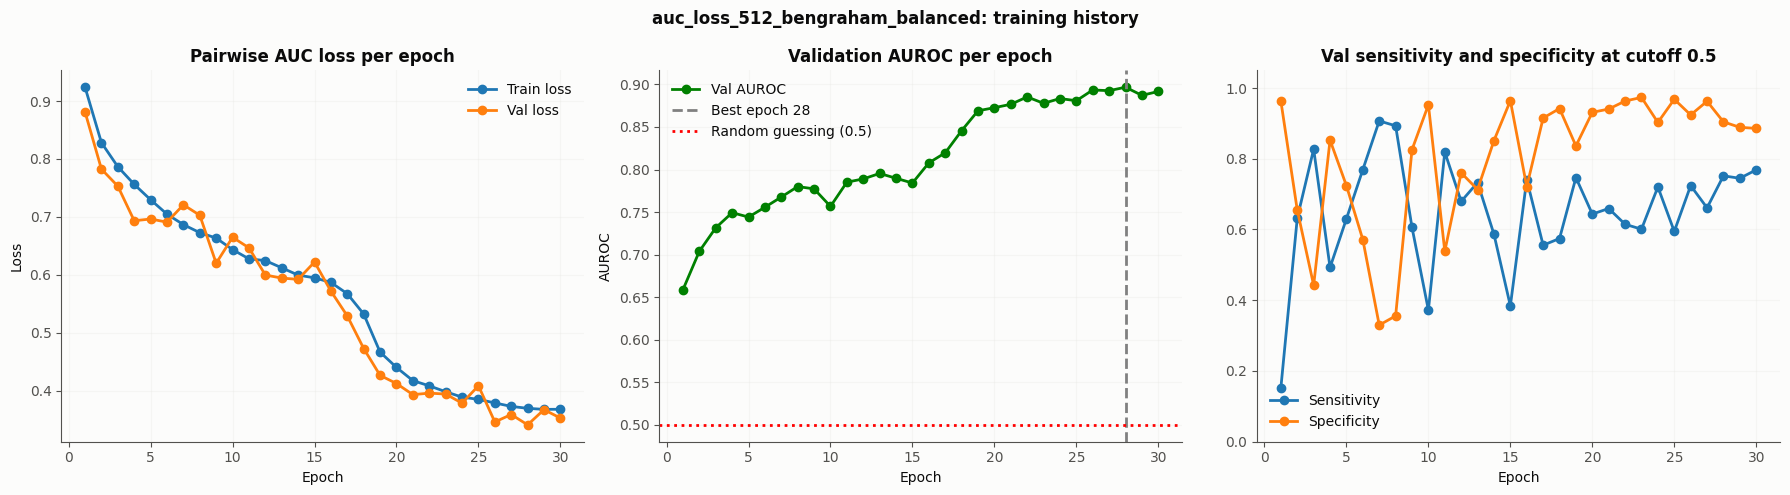

In [14]:
epochs = history["epoch"]
best_i = int(history["val_auroc"].idxmax())
best_epoch = int(history.loc[best_i, "epoch"])
print(f"Epochs trained: {len(history)} | best epoch {best_epoch} | best val AUROC {history.loc[best_i, 'val_auroc']:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].plot(epochs, history["train_loss"], marker="o", label="Train loss")
axes[0].plot(epochs, history["val_loss"], marker="o", label="Val loss")
axes[0].set_title("Pairwise AUC loss per epoch"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss")
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(epochs, history["val_auroc"], marker="o", color="green", label="Val AUROC")
axes[1].axvline(best_epoch, linestyle="--", color="gray", label=f"Best epoch {best_epoch}")
axes[1].axhline(0.5, linestyle=":", color="red", label="Random guessing (0.5)")
axes[1].set_title("Validation AUROC per epoch"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("AUROC")
axes[1].legend(); axes[1].grid(alpha=0.3)

axes[2].plot(epochs, history["val_sens@0.5"], marker="o", label="Sensitivity")
axes[2].plot(epochs, history["val_spec@0.5"], marker="o", label="Specificity")
axes[2].set_title("Val sensitivity and specificity at cutoff 0.5"); axes[2].set_xlabel("Epoch")
axes[2].set_ylim(0, 1.05); axes[2].legend(); axes[2].grid(alpha=0.3)

fig.suptitle(f"{RUN_NAME}: training history", fontweight="bold")
plt.tight_layout(); save_figure(fig, "01_training_curves"); plt.show()

Frozen threshold: 0.136
Val AUROC: 0.8967 | Val PR-AUC: 0.8193
At the frozen threshold on val -> sensitivity: 0.901 | specificity: 0.614 | precision: 0.431 | F1: 0.583
Confusion matrix (val) -> TN: 3003 | FP: 1889 | FN: 158 | TP: 1433
Saved threshold to: /kaggle/working/auc_loss_512_bengraham_balanced/evaluation/threshold.json


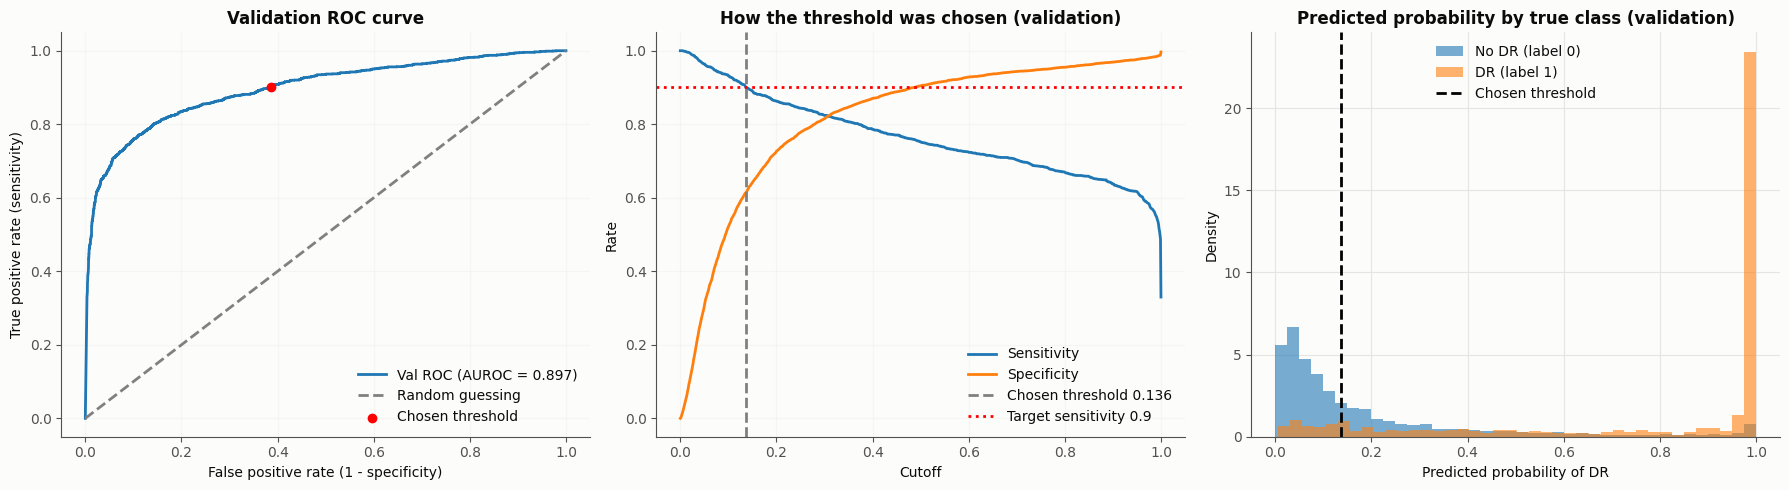

In [15]:
val_eval_loader = DataLoader(DRDataset(val_df, eval_tf), batch_size=64, shuffle=False,
                             num_workers=4, pin_memory=True)
val_probs = get_probs(best_model, val_eval_loader)
val_labels = val_df["label"].values
val_auroc = roc_auc_score(val_labels, val_probs)
val_pr_auc = average_precision_score(val_labels, val_probs)

thresholds = np.round(np.linspace(0, 1, 1001), 3)
sens_list, spec_list = [], []
for t in thresholds:
    s, c, _, _ = compute_rates(*count_outcomes(val_probs, val_labels, t))
    sens_list.append(s); spec_list.append(c)
ok = [t for t, s in zip(thresholds, sens_list) if s >= TARGET_SENSITIVITY]
frozen_threshold = float(max(ok)) if ok else 0.0

tp, tn, fp, fn = count_outcomes(val_probs, val_labels, frozen_threshold)
val_sens, val_spec, val_prec, val_f1 = compute_rates(tp, tn, fp, fn)
print("Frozen threshold:", frozen_threshold)
print("Val AUROC:", round(val_auroc, 4), "| Val PR-AUC:", round(val_pr_auc, 4))
print("At the frozen threshold on val -> sensitivity:", round(val_sens, 3), "| specificity:", round(val_spec, 3),
      "| precision:", round(val_prec, 3), "| F1:", round(val_f1, 3))
print(f"Confusion matrix (val) -> TN: {tn} | FP: {fp} | FN: {fn} | TP: {tp}")

saved = {"threshold": frozen_threshold, "target_sensitivity": TARGET_SENSITIVITY, "best_epoch": best_epoch,
         "val_auroc": float(val_auroc), "val_pr_auc": float(val_pr_auc), "val_sensitivity": float(val_sens),
         "val_specificity": float(val_spec), "val_precision": float(val_prec), "val_f1": float(val_f1)}
with open(THRESHOLD_PATH, "w") as f:
    json.dump(saved, f, indent=2)
print("Saved threshold to:", THRESHOLD_PATH)

fpr, tpr, _ = roc_curve(val_labels, val_probs)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].plot(fpr, tpr, label=f"Val ROC (AUROC = {val_auroc:.3f})")
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guessing")
axes[0].scatter([1 - val_spec], [val_sens], color="red", zorder=5, label="Chosen threshold")
axes[0].set_title("Validation ROC curve"); axes[0].set_xlabel("False positive rate (1 - specificity)")
axes[0].set_ylabel("True positive rate (sensitivity)"); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(thresholds, sens_list, label="Sensitivity")
axes[1].plot(thresholds, spec_list, label="Specificity")
axes[1].axvline(frozen_threshold, linestyle="--", color="gray", label=f"Chosen threshold {frozen_threshold}")
axes[1].axhline(TARGET_SENSITIVITY, linestyle=":", color="red", label=f"Target sensitivity {TARGET_SENSITIVITY}")
axes[1].set_title("How the threshold was chosen (validation)"); axes[1].set_xlabel("Cutoff"); axes[1].set_ylabel("Rate")
axes[1].legend(); axes[1].grid(alpha=0.3)

axes[2].hist(val_probs[val_labels == 0], bins=40, alpha=0.6, density=True, label="No DR (label 0)")
axes[2].hist(val_probs[val_labels == 1], bins=40, alpha=0.6, density=True, label="DR (label 1)")
axes[2].axvline(frozen_threshold, linestyle="--", color="black", label="Chosen threshold")
axes[2].set_title("Predicted probability by true class (validation)"); axes[2].set_xlabel("Predicted probability of DR")
axes[2].set_ylabel("Density"); axes[2].legend()
plt.tight_layout(); save_figure(fig, "02_validation_roc_and_threshold"); plt.show()

Using frozen threshold: 0.136

TEST RESULTS at threshold 0.136
Sensitivity: 0.8769
Specificity: 0.5979
Precision:   0.4131
F1:          0.5617
AUROC:       0.8778
PR-AUC:      0.7932
Confusion matrix -> TN: 2934 | FP: 1973 | FN: 195 | TP: 1389

Running bootstrap with 1000 resamples (about a minute)...

95% confidence intervals:
sensitivity: 0.8769 (0.8589 to 0.8955)
specificity: 0.5979 (0.5827 to 0.6147)
precision: 0.4131 (0.3937 to 0.4346)
f1: 0.5617 (0.5420 to 0.5823)
auroc: 0.8778 (0.8644 to 0.8901)
pr_auc: 0.7932 (0.7702 to 0.8159)

By source:
APTOS | n: 267 | sens: 1.000 | spec: 0.894 | precision: 0.906 | AUROC: 0.995
EyePACS | n: 6224 | sens: 0.865 | spec: 0.590 | precision: 0.390 | AUROC: 0.865

Sensitivity by DR grade:
Grade 1 | images: 348 | caught: 246 | sensitivity: 0.707
Grade 2 | images: 1004 | caught: 913 | sensitivity: 0.909
Grade 3 | images: 76 | caught: 76 | sensitivity: 1.000
Grade 4 | images: 156 | caught: 154 | sensitivity: 0.987


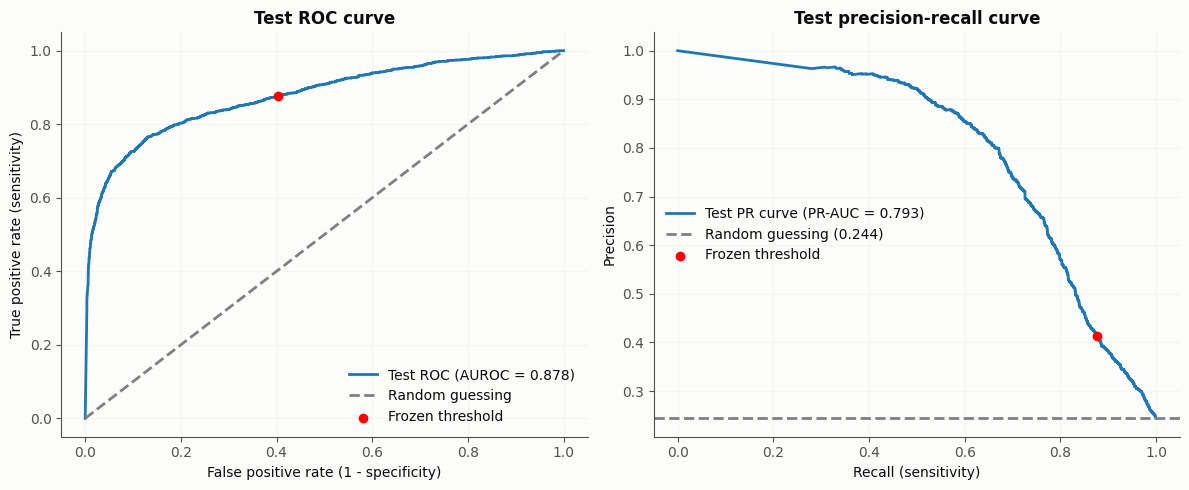

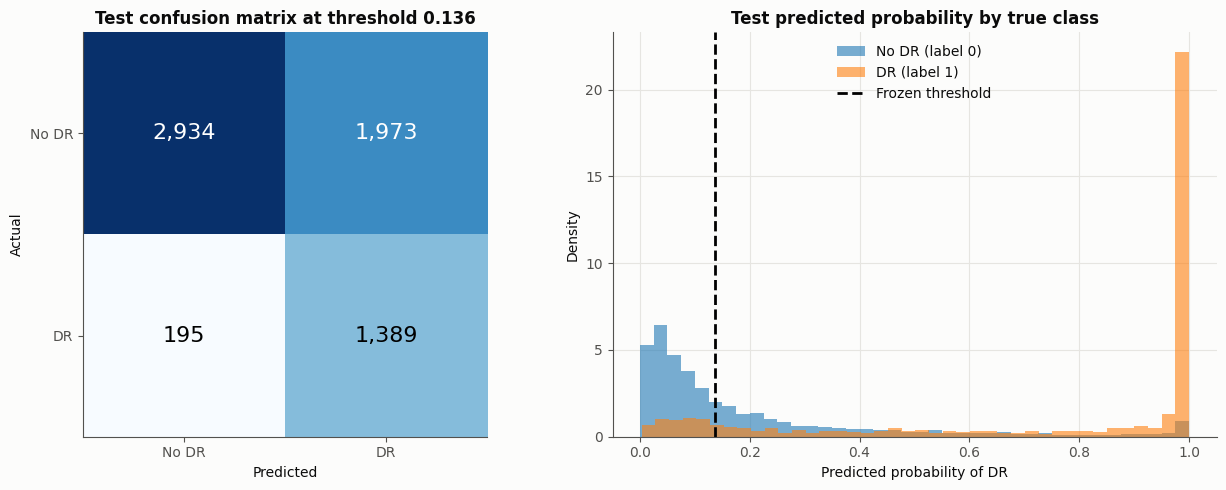

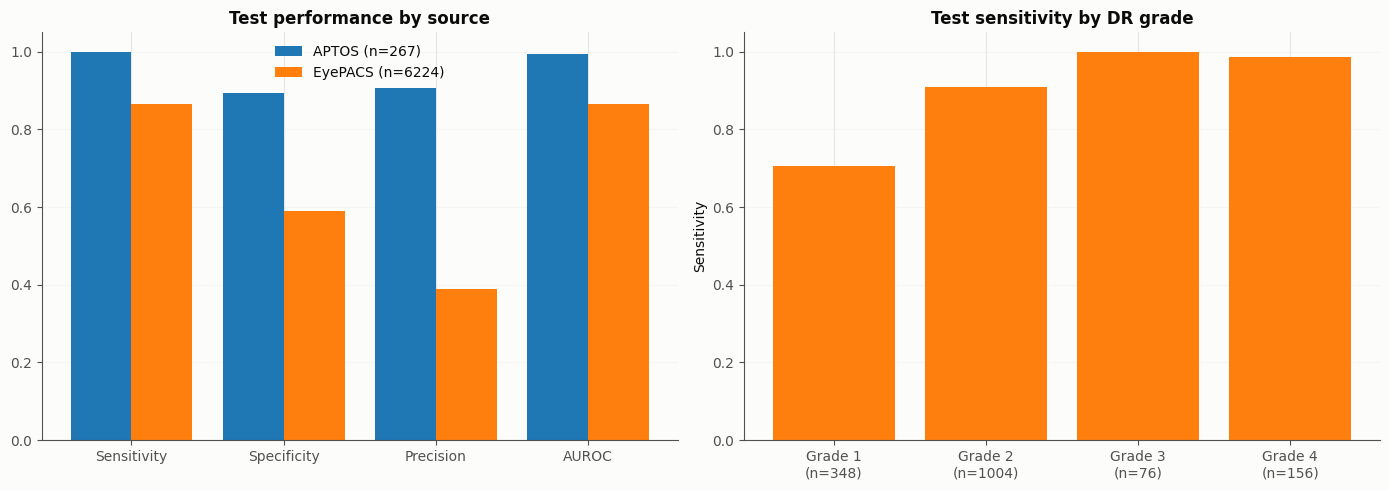

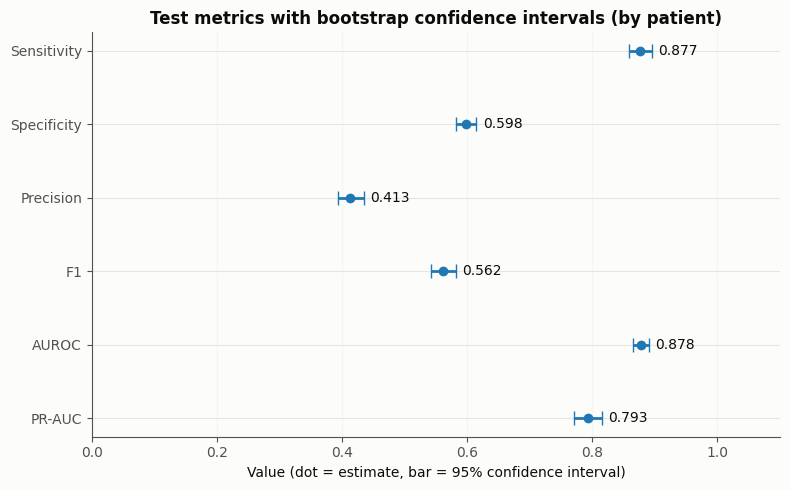


Total false negatives: 195


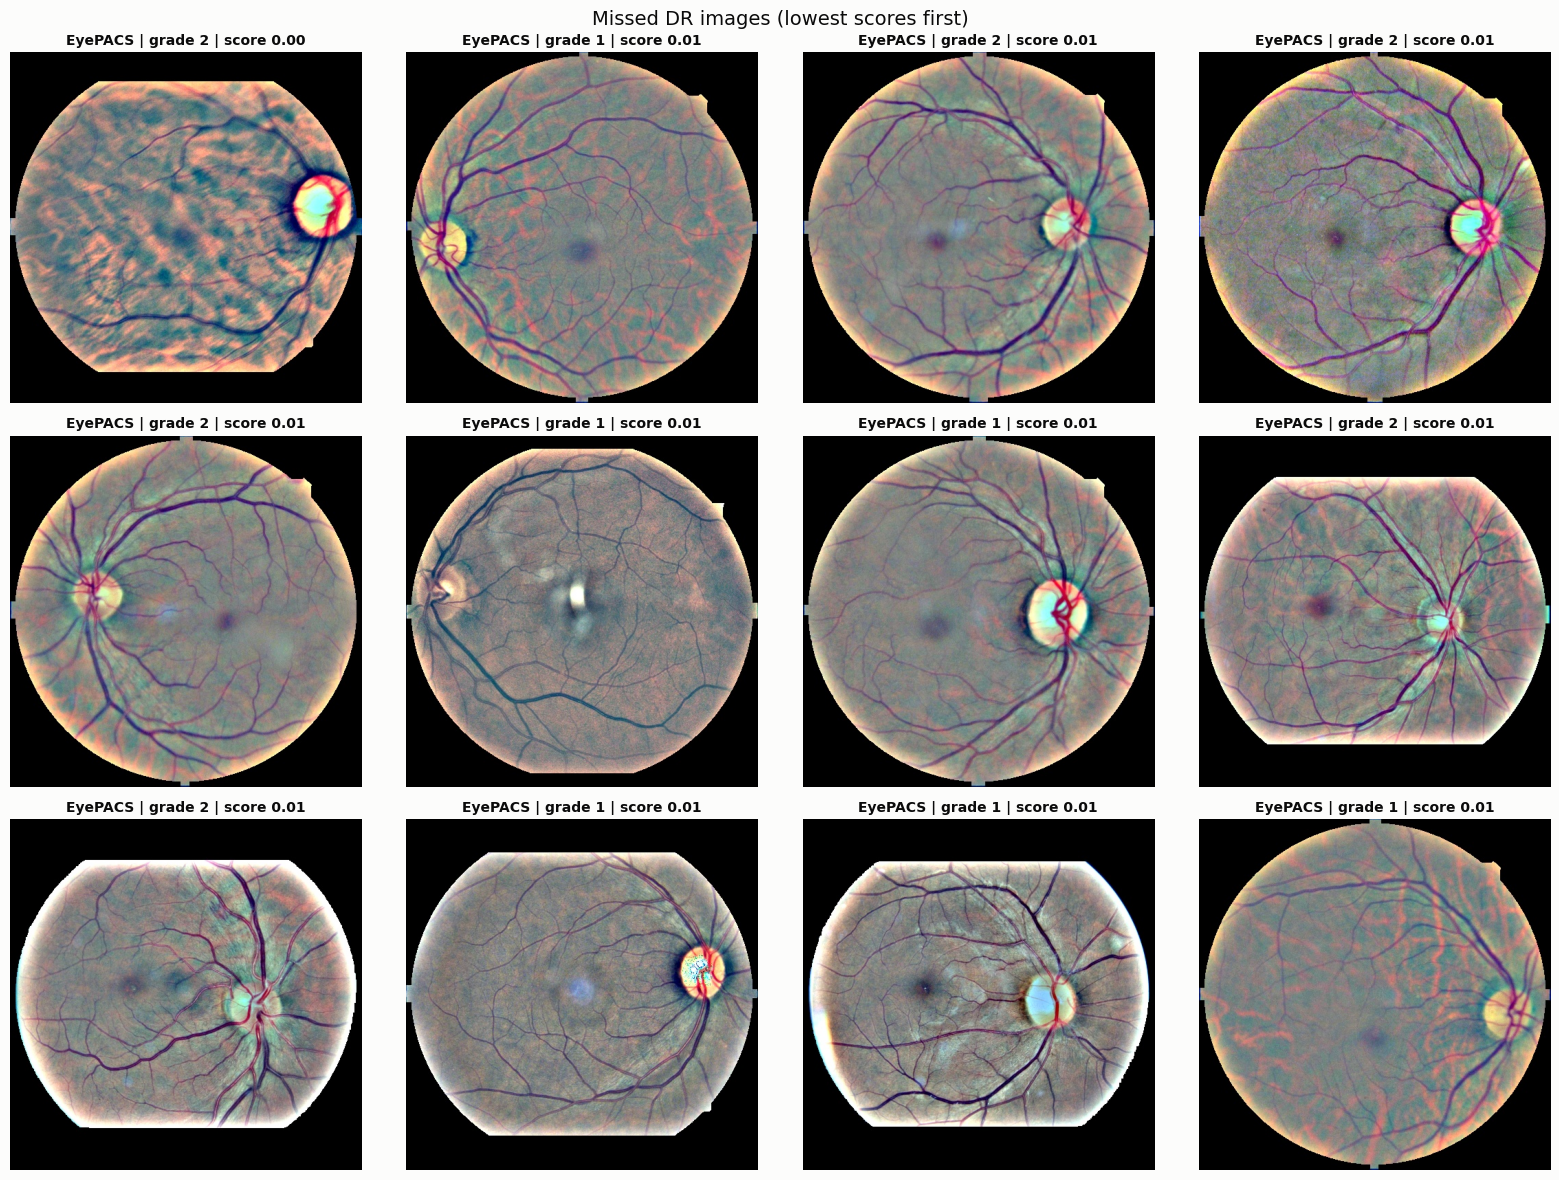


Saved results row to: /kaggle/working/auc_loss_512_bengraham_balanced/evaluation/results_row_auc_loss_512_bengraham_balanced.csv
Everything zipped to: /kaggle/working/auc_loss_512_bengraham_balanced_evaluation.zip


In [16]:
# ===== Cell E3: TEST evaluation with the frozen threshold (run ONCE, at the end) =====
with open(THRESHOLD_PATH) as f:
    saved = json.load(f)
frozen_threshold = saved["threshold"]
print("Using frozen threshold:", frozen_threshold)

test_loader = DataLoader(DRDataset(test_df, eval_tf), batch_size=64, shuffle=False, num_workers=4, pin_memory=True)
test_probs = get_probs(best_model, test_loader)
test_labels = test_df["label"].values
test_grades = test_df["grade"].values
test_sources = test_df["source"].values if "source" in test_df.columns else np.array(["all"] * len(test_df))
test_groups = test_df["group_id"].values if "group_id" in test_df.columns else np.arange(len(test_df))

# ---------- Main metrics ----------
tp, tn, fp, fn = count_outcomes(test_probs, test_labels, frozen_threshold)
test_sens, test_spec, test_prec, test_f1 = compute_rates(tp, tn, fp, fn)
test_auroc = roc_auc_score(test_labels, test_probs)
test_pr_auc = average_precision_score(test_labels, test_probs)
print("\nTEST RESULTS at threshold", frozen_threshold)
print("Sensitivity:", round(test_sens, 4)); print("Specificity:", round(test_spec, 4))
print("Precision:  ", round(test_prec, 4)); print("F1:         ", round(test_f1, 4))
print("AUROC:      ", round(test_auroc, 4)); print("PR-AUC:     ", round(test_pr_auc, 4))
print("Confusion matrix -> TN:", tn, "| FP:", fp, "| FN:", fn, "| TP:", tp)

# ---------- Save predictions ----------
test_pred = (test_probs >= frozen_threshold).astype(int)
pd.DataFrame({"filename": test_df["filename"], "source": test_sources, "group_id": test_groups,
              "grade": test_grades, "label": test_labels, "probability": test_probs,
              "predicted": test_pred}).to_csv(f"{EVAL_DIR}/test_predictions_{RUN_NAME}.csv", index=False)

# ---------- Bootstrap confidence intervals (resampled by patient) ----------
print(f"\nRunning bootstrap with {N_BOOTSTRAP} resamples (about a minute)...")
ci = bootstrap_ci(test_probs, test_labels, test_groups, frozen_threshold, N_BOOTSTRAP, SEED)
point_values = {"sensitivity": test_sens, "specificity": test_spec, "precision": test_prec,
                "f1": test_f1, "auroc": test_auroc, "pr_auc": test_pr_auc}
metric_keys = list(point_values)
metric_labels = ["Sensitivity", "Specificity", "Precision", "F1", "AUROC", "PR-AUC"]
print("\n95% confidence intervals:")
for k in metric_keys:
    print(f"{k}: {point_values[k]:.4f} ({ci[k][0]:.4f} to {ci[k][1]:.4f})")

# ---------- Breakdown by source ----------
source_rows = []
print("\nBy source:")
for src in sorted(set(test_sources)):
    m = test_sources == src
    s_sens, s_spec, s_prec, _ = compute_rates(*count_outcomes(test_probs[m], test_labels[m], frozen_threshold))
    s_auroc = roc_auc_score(test_labels[m], test_probs[m]) if 0 < test_labels[m].sum() < m.sum() else float("nan")
    source_rows.append({"source": src, "n": int(m.sum()), "sensitivity": s_sens, "specificity": s_spec,
                        "precision": s_prec, "auroc": s_auroc})
    print(f"{src} | n: {m.sum()} | sens: {s_sens:.3f} | spec: {s_spec:.3f} | precision: {s_prec:.3f} | AUROC: {s_auroc:.3f}")

# ---------- Sensitivity by DR grade ----------
grade_names = sorted(int(g) for g in set(test_grades[test_labels == 1]))
grade_sens, grade_totals = [], []
print("\nSensitivity by DR grade:")
for g in grade_names:
    m = (test_labels == 1) & (test_grades == g)
    caught = int((test_probs[m] >= frozen_threshold).sum())
    grade_sens.append(caught / m.sum()); grade_totals.append(int(m.sum()))
    print(f"Grade {g} | images: {m.sum()} | caught: {caught} | sensitivity: {caught / m.sum():.3f}")

# ---------- Figure 3: ROC and precision-recall ----------
fpr, tpr, _ = roc_curve(test_labels, test_probs)
precisions, recalls, _ = precision_recall_curve(test_labels, test_probs)
prevalence = test_labels.mean()
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(fpr, tpr, label=f"Test ROC (AUROC = {test_auroc:.3f})")
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guessing")
axes[0].scatter([1 - test_spec], [test_sens], color="red", zorder=5, label="Frozen threshold")
axes[0].set_title("Test ROC curve"); axes[0].set_xlabel("False positive rate (1 - specificity)")
axes[0].set_ylabel("True positive rate (sensitivity)"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(recalls, precisions, label=f"Test PR curve (PR-AUC = {test_pr_auc:.3f})")
axes[1].axhline(prevalence, linestyle="--", color="gray", label=f"Random guessing ({prevalence:.3f})")
axes[1].scatter([test_sens], [test_prec], color="red", zorder=5, label="Frozen threshold")
axes[1].set_title("Test precision-recall curve"); axes[1].set_xlabel("Recall (sensitivity)")
axes[1].set_ylabel("Precision"); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); save_figure(fig, "03_test_roc_and_pr"); plt.show()

# ---------- Figure 4: confusion matrix and score distribution ----------
matrix = np.array([[tn, fp], [fn, tp]])
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].imshow(matrix, cmap="Blues"); axes[0].grid(False)
for r in range(2):
    for c in range(2):
        axes[0].text(c, r, f"{matrix[r, c]:,}", ha="center", va="center", fontsize=16,
                     color="white" if matrix[r, c] > matrix.max() / 2 else "black")
axes[0].set_xticks([0, 1]); axes[0].set_xticklabels(["No DR", "DR"])
axes[0].set_yticks([0, 1]); axes[0].set_yticklabels(["No DR", "DR"])
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")
axes[0].set_title(f"Test confusion matrix at threshold {frozen_threshold}")
axes[1].hist(test_probs[test_labels == 0], bins=40, alpha=0.6, density=True, label="No DR (label 0)")
axes[1].hist(test_probs[test_labels == 1], bins=40, alpha=0.6, density=True, label="DR (label 1)")
axes[1].axvline(frozen_threshold, linestyle="--", color="black", label="Frozen threshold")
axes[1].set_title("Test predicted probability by true class"); axes[1].set_xlabel("Predicted probability of DR")
axes[1].set_ylabel("Density"); axes[1].legend()
plt.tight_layout(); save_figure(fig, "04_test_confusion_and_scores"); plt.show()

# ---------- Figure 5: by source and by grade ----------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
group_labels = ["Sensitivity", "Specificity", "Precision", "AUROC"]
bar_width = 0.8 / len(source_rows)
for k, row in enumerate(source_rows):
    vals = [row["sensitivity"], row["specificity"], row["precision"], row["auroc"]]
    axes[0].bar([m + k * bar_width for m in range(4)], vals, width=bar_width, label=f"{row['source']} (n={row['n']})")
axes[0].set_xticks([m + bar_width * (len(source_rows) - 1) / 2 for m in range(4)]); axes[0].set_xticklabels(group_labels)
axes[0].set_ylim(0, 1.05); axes[0].set_title("Test performance by source"); axes[0].legend(); axes[0].grid(axis="y", alpha=0.3)
axes[1].bar([f"Grade {g}\n(n={n})" for g, n in zip(grade_names, grade_totals)], grade_sens, color="tab:orange")
axes[1].set_ylim(0, 1.05); axes[1].set_ylabel("Sensitivity")
axes[1].set_title("Test sensitivity by DR grade"); axes[1].grid(axis="y", alpha=0.3)
plt.tight_layout(); save_figure(fig, "05_test_by_source_and_grade"); plt.show()

# ---------- Figure 6: metrics with 95% confidence intervals ----------
fig, ax = plt.subplots(figsize=(8, 5))
for k, key in enumerate(metric_keys):
    v, lo, hi = point_values[key], ci[key][0], ci[key][1]
    ax.errorbar(v, k, xerr=[[max(0.0, v - lo)], [max(0.0, hi - v)]], fmt="o", color="tab:blue", capsize=5)
    ax.text(max(hi, v) + 0.01, k, f"{v:.3f}", va="center")
ax.set_yticks(range(len(metric_labels))); ax.set_yticklabels(metric_labels); ax.invert_yaxis()
ax.set_xlim(0, 1.1); ax.set_xlabel("Value (dot = estimate, bar = 95% confidence interval)")
ax.set_title("Test metrics with bootstrap confidence intervals (by patient)"); ax.grid(axis="x", alpha=0.3)
plt.tight_layout(); save_figure(fig, "06_test_metrics_with_ci"); plt.show()

# ---------- Figure 7: false negative gallery ----------
miss = np.where((test_labels == 1) & (test_probs < frozen_threshold))[0]
miss = miss[np.argsort(test_probs[miss])]
print("\nTotal false negatives:", len(miss))
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for k, ax in enumerate(axes.flat):
    ax.axis("off")
    if k < len(miss):
        i = miss[k]
        ax.imshow(Image.open(test_df["path"].iloc[i]).convert("RGB"))
        ax.set_title(f"{test_sources[i]} | grade {test_grades[i]} | score {test_probs[i]:.2f}", fontsize=10)
fig.suptitle("Missed DR images (lowest scores first)", fontsize=14)
plt.tight_layout(); save_figure(fig, "07_false_negative_gallery"); plt.show()

# ---------- Save one results row for the team table + zip everything ----------
summary_row = {"run": RUN_NAME, "loss": "pairwise AUC", "seed": SEED, "image_size": IMG_SIZE,
               "preprocessing": "Ben Graham", "train_balanced": bool(IS_BALANCED),
               "best_epoch": saved["best_epoch"], "epochs_trained": int(len(history)), "threshold": frozen_threshold,
               "val_auroc": round(saved["val_auroc"], 4), "val_sensitivity": round(saved["val_sensitivity"], 4),
               "val_specificity": round(saved["val_specificity"], 4)}
for k in metric_keys:
    summary_row["test_" + k] = round(point_values[k], 4)
    summary_row["test_" + k + "_ci"] = f"{ci[k][0]:.3f} to {ci[k][1]:.3f}"
pd.DataFrame([summary_row]).to_csv(f"{EVAL_DIR}/results_row_{RUN_NAME}.csv", index=False)
print("\nSaved results row to:", f"{EVAL_DIR}/results_row_{RUN_NAME}.csv")

zip_path = shutil.make_archive(f"/kaggle/working/{RUN_NAME}_evaluation", "zip", EVAL_DIR)
print("Everything zipped to:", zip_path)